In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings; warnings.filterwarnings("ignore")
%matplotlib inline
from sklearn.model_selection import train_test_split, cross_validate
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, roc_curve, roc_auc_score)

In [4]:
df = pd.read_csv("Titanic-Dataset.csv")      # Titanic (Kaggle train.csv) - keep it in the same folder as this notebook
print("Rows:", df.shape[0], " Columns:", df.shape[1])
df.head()

Rows: 891  Columns: 12


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [5]:
target = "Survived"
positive_class = 1                                  # 1 = survived
df["Sex_male"] = (df["Sex"] == "male").astype(int)  # encode Sex numerically
predictors = ["Pclass", "Sex_male", "Age", "SibSp", "Parch", "Fare"]
model_df = df[[target] + predictors].dropna()       # drops the rows with missing Age
print("Number of classes:", model_df[target].nunique())
X = model_df[predictors]
y = (model_df[target] == positive_class).astype(int)
print("Rows used:", len(model_df))
print("Class mapping: 1 = Survived | 0 = Did not survive")
print((y.value_counts(normalize=True)*100).round(2))

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)
print("Training:", len(X_train), " Testing:", len(X_test))

Number of classes: 2
Rows used: 714
Class mapping: 1 = Survived | 0 = Did not survive
Survived
0    59.38
1    40.62
Name: proportion, dtype: float64
Training: 571  Testing: 143


In [6]:
results, preds, probs = [], {}, {}
def evaluate(name, model):
    model.fit(X_train, y_train)                 # no scaling needed for trees
    preds[name] = model.predict(X_test)
    probs[name] = model.predict_proba(X_test)[:, 1]
    results.append({"Model": name,
        "Train Accuracy": accuracy_score(y_train, model.predict(X_train)),
        "Accuracy": accuracy_score(y_test, preds[name]),
        "Precision": precision_score(y_test, preds[name], zero_division=0),
        "Recall": recall_score(y_test, preds[name], zero_division=0),
        "F1": f1_score(y_test, preds[name], zero_division=0),
        "AUC": roc_auc_score(y_test, probs[name])})
    print(name, {k: round(v, 4) for k, v in results[-1].items() if k != "Model"})
    return model

In [7]:
dt = evaluate("Decision Tree (full)", DecisionTreeClassifier(criterion="gini", random_state=42))
print("Depth:", dt.get_depth(), " Leaves:", dt.get_n_leaves())

Decision Tree (full) {'Train Accuracy': 0.9895, 'Accuracy': 0.7273, 'Precision': 0.6667, 'Recall': 0.6552, 'F1': 0.6609, 'AUC': 0.7097}
Depth: 17  Leaves: 131


Decision Tree (restricted) {'Train Accuracy': 0.8581, 'Accuracy': 0.7413, 'Precision': 0.7143, 'Recall': 0.6034, 'F1': 0.6542, 'AUC': 0.8256}
Depth: 5  Leaves: 24


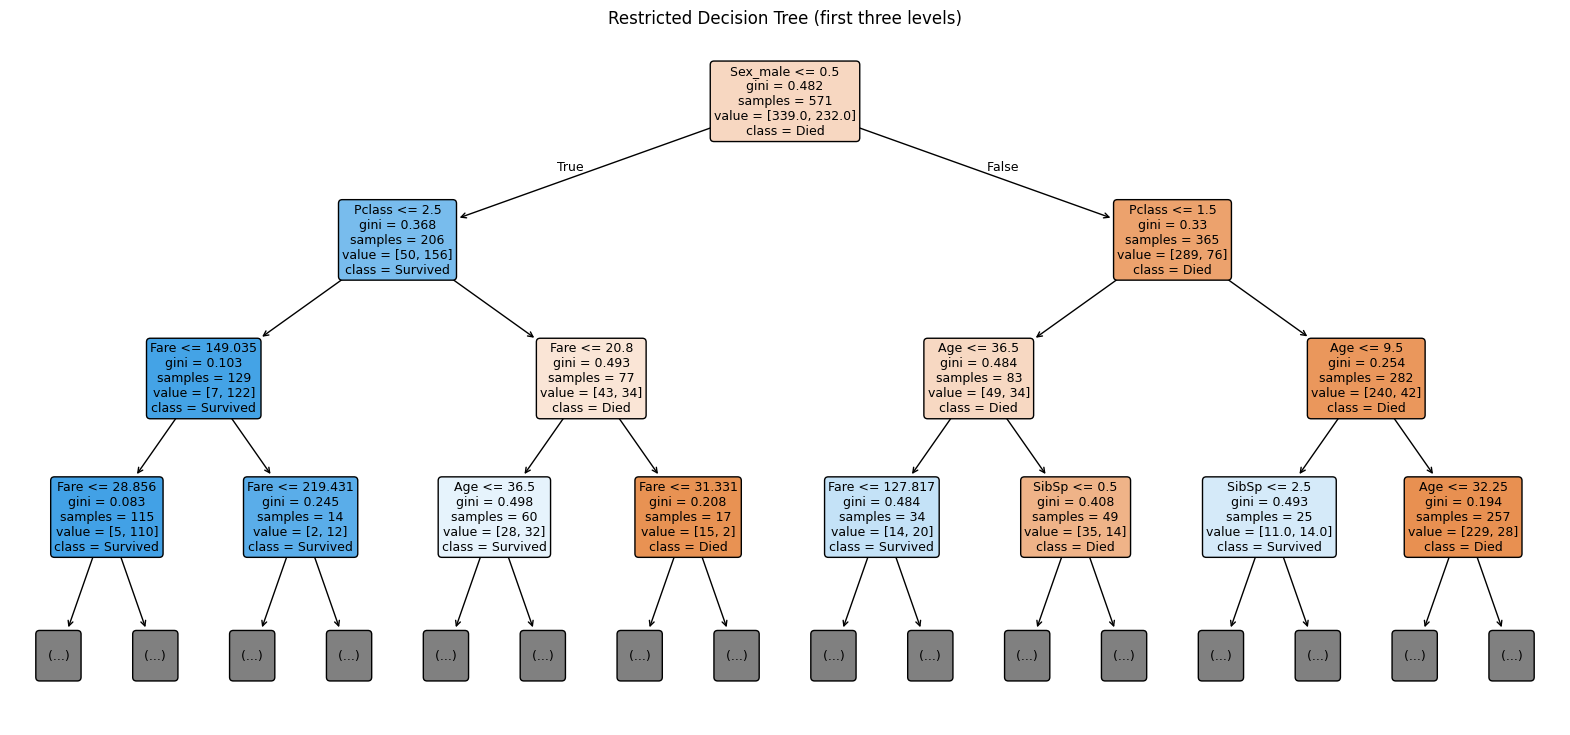

In [8]:
dt_small = evaluate("Decision Tree (restricted)",
    DecisionTreeClassifier(criterion="gini", max_depth=5, min_samples_split=10, min_samples_leaf=5, random_state=42))
print("Depth:", dt_small.get_depth(), " Leaves:", dt_small.get_n_leaves())
plt.figure(figsize=(20, 9))
plot_tree(dt_small, max_depth=3, feature_names=predictors, class_names=["Died", "Survived"],
          filled=True, rounded=True, fontsize=9)
plt.title("Restricted Decision Tree (first three levels)"); plt.show()

In [9]:
rf = evaluate("Random Forest", RandomForestClassifier(n_estimators=100, oob_score=True, random_state=42, n_jobs=-1))
print("Out-of-bag score:", round(rf.oob_score_, 4))

Random Forest {'Train Accuracy': 0.9895, 'Accuracy': 0.7552, 'Precision': 0.7018, 'Recall': 0.6897, 'F1': 0.6957, 'AUC': 0.8285}
Out-of-bag score: 0.8196


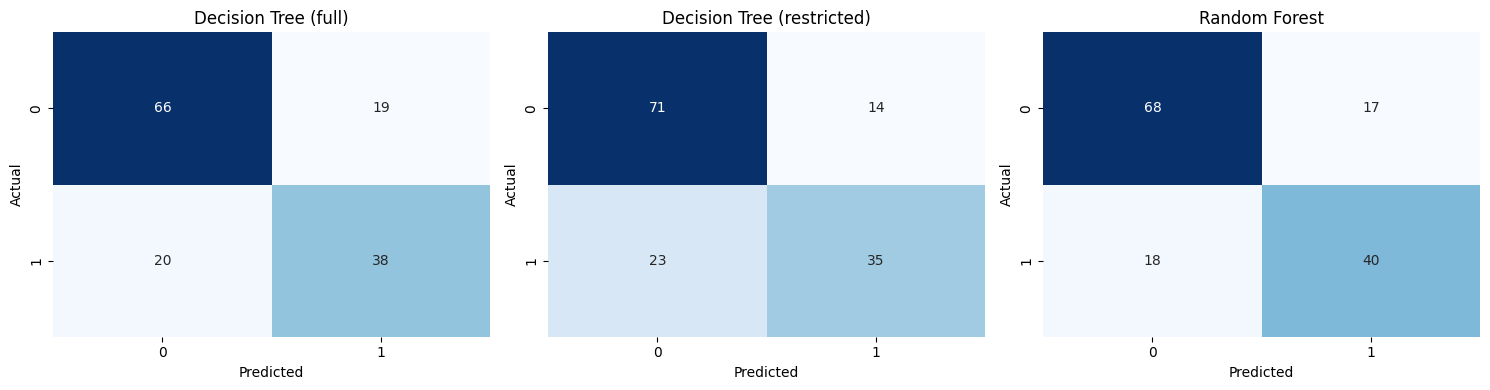

================== Decision Tree (full) ==================
              precision    recall  f1-score   support

           0       0.77      0.78      0.77        85
           1       0.67      0.66      0.66        58

    accuracy                           0.73       143
   macro avg       0.72      0.72      0.72       143
weighted avg       0.73      0.73      0.73       143

================== Decision Tree (restricted) ==================
              precision    recall  f1-score   support

           0       0.76      0.84      0.79        85
           1       0.71      0.60      0.65        58

    accuracy                           0.74       143
   macro avg       0.73      0.72      0.72       143
weighted avg       0.74      0.74      0.74       143

================== Random Forest ==================
              precision    recall  f1-score   support

           0       0.79      0.80      0.80        85
           1       0.70      0.69      0.70        58

    ac

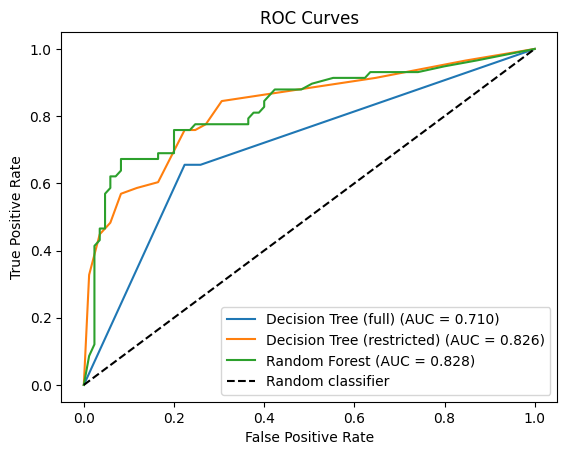

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, pred) in zip(axes, preds.items()):
    sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
    ax.set(title=name, xlabel="Predicted", ylabel="Actual")
plt.tight_layout(); plt.show()
for name, pred in preds.items():
    print("="*18, name, "="*18)
    print(classification_report(y_test, pred, zero_division=0))
for name, prob in probs.items():
    fpr, tpr, _ = roc_curve(y_test, prob)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_test, prob):.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random classifier")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate"); plt.title("ROC Curves"); plt.legend(); plt.show()

,Decision Tree,Random Forest,Permutation (mean),Permutation (std)
Fare,0.2338,0.2860,0.0070,0.0269
Age,0.2504,0.2818,0.0112,0.0105
Sex_male,0.2946,0.2439,0.1497,0.0376
Pclass,0.1279,0.1028,0.0126,0.0214
SibSp,0.0655,0.0483,-0.0168,0.0163
Parch,0.0277,0.0372,-0.0238,0.0163


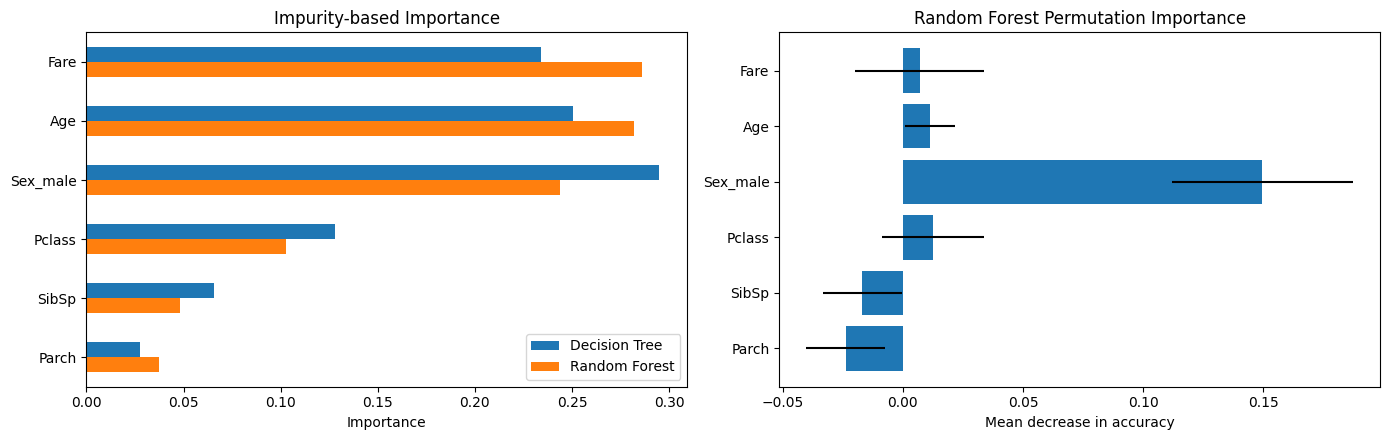

In [11]:
perm = permutation_importance(rf, X_test, y_test, n_repeats=10, scoring="accuracy", random_state=42)
importance = pd.DataFrame({"Decision Tree": dt.feature_importances_,
                           "Random Forest": rf.feature_importances_,
                           "Permutation (mean)": perm.importances_mean,
                           "Permutation (std)": perm.importances_std},
                          index=predictors).sort_values("Random Forest", ascending=False)
display(importance.round(4))
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
importance[["Decision Tree", "Random Forest"]].plot(kind="barh", ax=axes[0])
axes[0].set(title="Impurity-based Importance", xlabel="Importance"); axes[0].invert_yaxis()
axes[1].barh(importance.index, importance["Permutation (mean)"], xerr=importance["Permutation (std)"])
axes[1].set(title="Random Forest Permutation Importance", xlabel="Mean decrease in accuracy"); axes[1].invert_yaxis()
plt.tight_layout(); plt.show()

,Trees,CV Accuracy,CV F1,CV AUC
0,10,0.8144,0.7576,0.8507
1,25,0.8196,0.7681,0.8640
2,50,0.8283,0.7806,0.8663
3,100,0.8231,0.7749,0.8689
4,200,0.8231,0.7772,0.8693


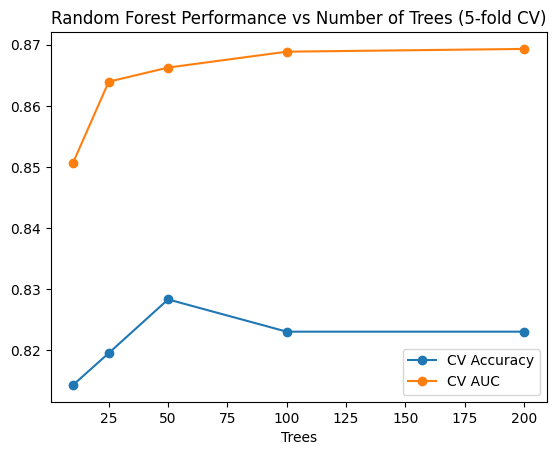

In [12]:
tree_rows = []
for n in [10, 25, 50, 100, 200]:
    cv = cross_validate(RandomForestClassifier(n_estimators=n, random_state=42, n_jobs=-1),
                        X_train, y_train, cv=5, scoring=["accuracy", "f1", "roc_auc"])
    tree_rows.append({"Trees": n, "CV Accuracy": cv["test_accuracy"].mean(),
                      "CV F1": cv["test_f1"].mean(), "CV AUC": cv["test_roc_auc"].mean()})
tree_results = pd.DataFrame(tree_rows)
display(tree_results.round(4))
tree_results.plot(x="Trees", y=["CV Accuracy", "CV AUC"], marker="o")
plt.title("Random Forest Performance vs Number of Trees (5-fold CV)"); plt.show()

,Train Accuracy,Accuracy,Precision,Recall,F1,AUC
Model,,,,,,
Decision Tree (full),0.9895,0.7273,0.6667,0.6552,0.6609,0.7097
Decision Tree (restricted),0.8581,0.7413,0.7143,0.6034,0.6542,0.8256
Random Forest,0.9895,0.7552,0.7018,0.6897,0.6957,0.8285


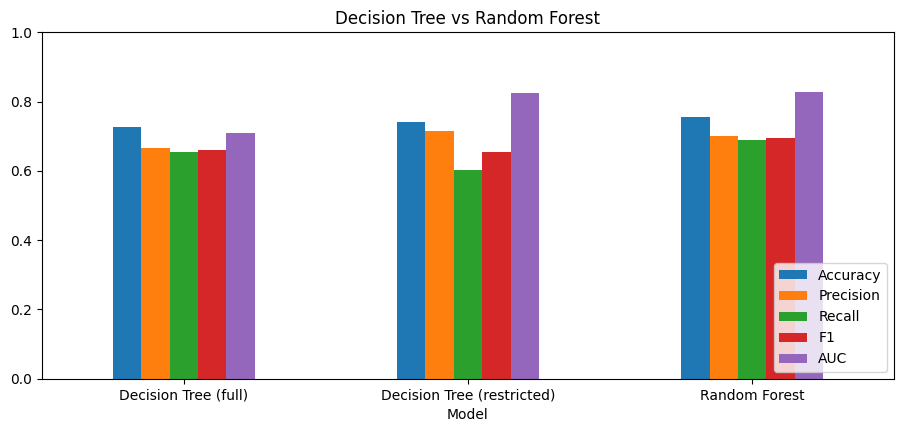

In [13]:
comparison = pd.DataFrame(results).set_index("Model")
display(comparison.round(4))
comparison.drop(columns="Train Accuracy").plot(kind="bar", rot=0, figsize=(11, 4.5), ylim=(0, 1))
plt.title("Decision Tree vs Random Forest"); plt.legend(loc="lower right"); plt.show()
comparison.to_csv("Experiment_9_Model_Results.csv")
importance.to_csv("Experiment_9_Feature_Importance.csv")
tree_results.to_csv("Experiment_9_Tree_Count.csv", index=False)